# Exercise - Multiple Linear Regression



It's time for you to apply your knowledge to a new dataset. So that not too much changes come at once, we will stick to the cars topic and work with the **car seats data**. A company that makes car seats would like to construct a model to predict sales and they need your help!

You will find the file called `carseats.csv` in the data folder. It contains 400 observations on the following 11 variables:
* **Sales**:         Unit sales (in thousands) at each location
* **CompPrice**:     Price charged by competitor at each location
* **Income**:        Community income level (in thousands of dollars)
* **Advertising**:   Local advertising budget for company at each location (in thousands of dollars)
* **Population**:    Population size in region (in thousands)
* **Price**:         Price company charges for car seats at each site
* **ShelveLoc**:     A factor with levels Bad, Good and Medium indicating the quality of the shelving location for the car seats at each site
* **Age**:           Average age of the local population
* **Education**:     Education level at each location
* **Urban**:         A factor with levels No and Yes to indicate whether the store is in an urban or rural location
* **US**:            A factor with levels No and Yes to indicate whether the store is in the US or not

**(a) Load the data**

In [1]:
# Tools for this exercise
import itertools
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

# Load the car seat sales data (400 stores, 11 columns)
carseats = pd.read_csv("data/carseats.csv")
print(carseats.shape)
carseats.head()

(400, 11)


,Sales,CompPrice,Income,Advertising,Population,Price,ShelveLoc,Age,Education,Urban,US
0,9.50,138,73,11,276,120,Bad,42,17,Yes,Yes
1,11.22,111,48,16,260,83,Good,65,10,Yes,Yes
2,10.06,113,35,10,269,80,Medium,59,12,Yes,Yes
3,7.40,117,100,4,466,97,Medium,55,14,Yes,Yes
4,4.15,141,64,3,340,128,Bad,38,13,Yes,No


In [2]:
# Which columns are numbers and which are text categories?
carseats.info()

<class 'pandas.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Data columns (total 11 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Sales        400 non-null    float64
 1   CompPrice    400 non-null    int64  
 2   Income       400 non-null    int64  
 3   Advertising  400 non-null    int64  
 4   Population   400 non-null    int64  
 5   Price        400 non-null    int64  
 6   ShelveLoc    400 non-null    str    
 7   Age          400 non-null    int64  
 8   Education    400 non-null    int64  
 9   Urban        400 non-null    str    
 10  US           400 non-null    str    
dtypes: float64(1), int64(7), str(3)
memory usage: 34.5 KB


**(b) Visualize the data with the appropriate plots.** 

<br>
<details><summary>
Click here for a hint…
</summary>
Check the documentation for seaborn's pair plots. 
</details>

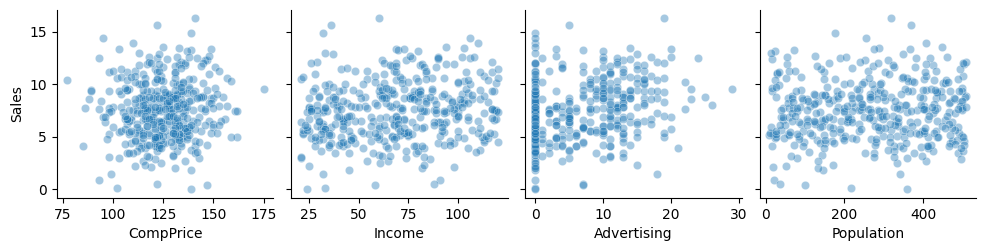

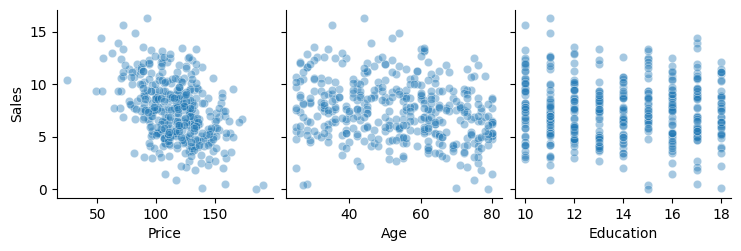

In [3]:
# One small scatter plot of Sales against every numeric column
numeric = carseats.select_dtypes("number").columns.drop("Sales")
sns.pairplot(carseats, x_vars=numeric[:4], y_vars=["Sales"],
             plot_kws={"alpha": 0.4})
sns.pairplot(carseats, x_vars=numeric[4:], y_vars=["Sales"],
             plot_kws={"alpha": 0.4});

In [4]:
# Correlation of every numeric column with Sales, strongest first
carseats[numeric].corrwith(carseats["Sales"]).sort_values()

Price         -0.444951
Age           -0.231815
Education     -0.051955
Population     0.050471
CompPrice      0.064079
Income         0.151951
Advertising    0.269507
dtype: float64

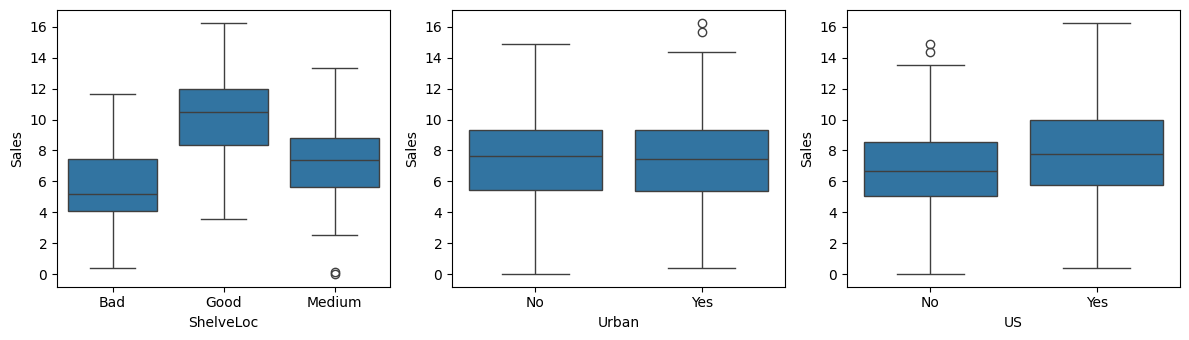

In [5]:
# The three text columns: average Sales per category
fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))
for col, ax in zip(["ShelveLoc", "Urban", "US"], axes):
    sns.boxplot(data=carseats, x=col, y="Sales", ax=ax,
                order=sorted(carseats[col].unique()))
plt.tight_layout()

**(c) What trends do you see in the data?**

In [6]:
# Average sales per category of the three text columns
for col in ["ShelveLoc", "Urban", "US"]:
    print(carseats.groupby(col)["Sales"].mean().round(2).to_dict())

{'Bad': 5.52, 'Good': 10.21, 'Medium': 7.31}
{'No': 7.56, 'Yes': 7.47}
{'No': 6.82, 'Yes': 7.87}


**Answer (c):**
- **Price** is the clearest trend: higher price, lower sales (correlation -0.44).
- **Advertising** (+0.27) and **Income** (+0.15) go mildly with higher sales; **Age** (-0.23) mildly with lower sales.
- **CompPrice, Population, Education** show almost no trend on their own (correlations between -0.06 and +0.07).
- **ShelveLoc** matters a lot: average sales are 10.21 (Good shelf), 7.31 (Medium) and 5.52 (Bad), in thousands of units.
- **US** stores sell a bit more (7.87 vs 6.82); **Urban** makes almost no difference (7.47 vs 7.56).
- The numeric columns do not look strongly related to each other, so no obvious multicollinearity.

**(d) Find the single best predictor for a simple linear regression.**

<br>
<details><summary>
Click here for a hint…
</summary>
Fit a linear model to all possible explanatory variables and pick best one.
</details>

In [7]:
# Fit one simple model per numeric column and keep its R-squared
y = carseats["Sales"]
single = {}
for col in numeric:
    X = carseats[[col]]
    model = LinearRegression().fit(X, y)
    single[col] = r2_score(y, model.predict(X))

single = pd.Series(single).sort_values(ascending=False)
single.round(4)

Price          0.1980
Advertising    0.0726
Age            0.0537
Income         0.0231
CompPrice      0.0041
Education      0.0027
Population     0.0025
dtype: float64

In [8]:
# Best single predictor and its line
best = single.index[0]
model = LinearRegression().fit(carseats[[best]], y)
print("Best single predictor:", best)
print("Intercept:", round(model.intercept_, 3),
      " Slope:", round(model.coef_[0], 4))

Best single predictor: Price
Intercept: 13.642  Slope: -0.0531


**Answer (d):** **Price** is the best single predictor with $R^2 = 0.198$: price alone explains about 20 % of the variation in sales. Each \$1 higher price goes with about 0.053 thousand (53) fewer units sold. All other single features explain less than 8 %.

**(e) Fit a model with all possible explanatory variables.**

In [9]:
# Adjusted R-squared helper (same formula as in notebook 4)
def adjusted_r_squared(r_squared, X):
    n, p = X.shape
    return 1 - (1 - r_squared) * (n - 1) / (n - p - 1)


# All 7 numeric columns at once
X_all = carseats[numeric]
model_all = LinearRegression().fit(X_all, y)
r2_all = r2_score(y, model_all.predict(X_all))
print("R-squared, all numeric features:", round(r2_all, 4))
pd.Series(model_all.coef_, index=numeric).round(4)

R-squared, all numeric features: 0.5417


CompPrice      0.0939
Income         0.0129
Advertising    0.1309
Population    -0.0001
Price         -0.0925
Age           -0.0450
Education     -0.0400
dtype: float64

**Answer (e):** All 7 numeric features together reach $R^2 = 0.5417$, much more than Price alone (0.198). The three text columns (ShelveLoc, Urban, US) cannot go into a linear regression as words; they need dummy columns first (notebook 6). See the follow-up in (i).

**(f) What's the best model according to $R^2$?**

In [10]:
# Try every combination of the 7 numeric columns (127 models)
rows = []
for k in range(1, len(numeric) + 1):
    for combo in itertools.combinations(numeric, k):
        X = carseats[list(combo)]
        r2 = r2_score(y, LinearRegression().fit(X, y).predict(X))
        rows.append({"features": ", ".join(combo), "n": k, "r2": r2,
                     "adj_r2": adjusted_r_squared(r2, X)})
combos = pd.DataFrame(rows)

# Best model by plain R-squared
combos.sort_values("r2", ascending=False).head(3).round(4)

,features,n,r2,adj_r2
126,"CompPrice, Income, Advertising, Population, Pr...",7,0.5417,0.5335
122,"CompPrice, Income, Advertising, Price, Age, Ed...",6,0.5416,0.5346
119,"CompPrice, Income, Advertising, Population, Pr...",6,0.5403,0.5333


**Answer (f):** The model with **all 7 numeric features** has the highest $R^2$ (0.5417). This is always the case: adding a feature can never lower plain $R^2$, so the biggest model always "wins". That is exactly why $R^2$ is a poor judge for comparing models of different size.

**(g) Remove a couple of explanatory variables. How does $R^2$ change?**

In [11]:
# Drop the two weakest columns (Population, Education), then drop more
drop_steps = [[], ["Population"], ["Population", "Education"],
              ["Population", "Education", "CompPrice"]]
for dropped in drop_steps:
    cols = [c for c in numeric if c not in dropped]
    X = carseats[cols]
    r2 = r2_score(y, LinearRegression().fit(X, y).predict(X))
    print(f"{len(cols)} features, dropped {dropped or 'nothing'}:"
          f" R2 = {r2:.4f}")

7 features, dropped nothing: R2 = 0.5417
6 features, dropped ['Population']: R2 = 0.5416
5 features, dropped ['Population', 'Education']: R2 = 0.5403
4 features, dropped ['Population', 'Education', 'CompPrice']: R2 = 0.3709


**Answer (g):** Dropping **Population** barely changes $R^2$ (0.5417 to 0.5416), and dropping **Education** as well gives 0.5403: these two carry almost no information. Dropping **CompPrice** too makes $R^2$ fall sharply to 0.3709. CompPrice looks useless on its own (correlation 0.06), but next to Price it matters a lot: what counts is our price *compared with* the competitor's.

**(h) Repeat the process for the adjusted $R^2$.**

In [12]:
# Same removals, now judged by adjusted R-squared
for dropped in drop_steps:
    cols = [c for c in numeric if c not in dropped]
    X = carseats[cols]
    r2 = r2_score(y, LinearRegression().fit(X, y).predict(X))
    print(f"{len(cols)} features, dropped {dropped or 'nothing'}:"
          f" adj. R2 = {adjusted_r_squared(r2, X):.4f}")

7 features, dropped nothing: adj. R2 = 0.5335
6 features, dropped ['Population']: adj. R2 = 0.5346
5 features, dropped ['Population', 'Education']: adj. R2 = 0.5345
4 features, dropped ['Population', 'Education', 'CompPrice']: adj. R2 = 0.3645


In [13]:
# Best model of all 127 by adjusted R-squared
combos.sort_values("adj_r2", ascending=False).head(3).round(4)

,features,n,r2,adj_r2
122,"CompPrice, Income, Advertising, Price, Age, Ed...",6,0.5416,0.5346
101,"CompPrice, Income, Advertising, Price, Age",5,0.5403,0.5345
126,"CompPrice, Income, Advertising, Population, Pr...",7,0.5417,0.5335


**Answer (h):** Adjusted $R^2$ rewards dropping the useless feature: 0.5335 (all 7), **0.5346 (without Population, the best)**, 0.5345 (without Population and Education), 0.3645 (also without CompPrice). Over all 127 combinations the best by adjusted $R^2$ is the 6-feature model **CompPrice, Income, Advertising, Price, Age, Education**.

**(i) What are your most interesting findings?**

In [14]:
# Follow-up: add the 3 text columns as 0/1 dummy columns (notebook 6)
dummies = pd.get_dummies(carseats, drop_first=True, dtype=int)
X_dum = dummies.drop(columns="Sales")
model_dum = LinearRegression().fit(X_dum, y)
r2_dum = r2_score(y, model_dum.predict(X_dum))
print("Columns:", list(X_dum.columns))
print("R-squared:", round(r2_dum, 4),
      " adj. R-squared:", round(adjusted_r_squared(r2_dum, X_dum), 4))
pd.Series(model_dum.coef_, index=X_dum.columns).round(3)

Columns: ['CompPrice', 'Income', 'Advertising', 'Population', 'Price', 'Age', 'Education', 'ShelveLoc_Good', 'ShelveLoc_Medium', 'Urban_Yes', 'US_Yes']
R-squared: 0.8734  adj. R-squared: 0.8698


CompPrice           0.093
Income              0.016
Advertising         0.123
Population          0.000
Price              -0.095
Age                -0.046
Education          -0.021
ShelveLoc_Good      4.850
ShelveLoc_Medium    1.957
Urban_Yes           0.123
US_Yes             -0.184
dtype: float64

**Answer (i):**
1. **Features work as a team.** CompPrice is worthless alone ($R^2$ 0.004) but dropping it from the 5-feature model (step g) costs 17 points of $R^2$ (0.540 to 0.371). Price relative to the competitor drives sales.
2. **Plain $R^2$ always prefers the biggest model**; adjusted $R^2$ picked a 6-feature model and dropped Population.
3. **The text columns hold the most signal.** With dummy columns for ShelveLoc, Urban and US, $R^2$ jumps from 0.54 to **0.873** (adjusted 0.870). A Good shelf adds about 4.85 thousand units compared with a Bad shelf, holding everything else constant; a Medium shelf about 1.96 thousand. Urban and US add almost nothing once the rest is known.
4. For the company: **shelf placement and price** are the two big levers; advertising helps (about +0.12 thousand units per \$1000).

*Note: all $R^2$ values here are measured on the same data the model was trained on. A fair test on unseen data comes in a later session.*

<br>
<br> 
<br>

----